In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid', context='notebook')
from matplotlib.ticker import FuncFormatter

# Read in data

The dataset, `cars.csv`, contains cleaned and processed data. If you want to make changes, the notebook, `materialize.ipynb`, creates the data from the raw source datsets. 

In [23]:
DATA = Path('../data') # notebooks run from their own folder (src/)
RES = Path('../res/market size') # notebooks run from their own folder (src/)
RES.mkdir(parents=True, exist_ok=True)

In [28]:
# %% Read in data
cars = pd.read_csv(DATA / 'cars.csv')

lbl_vars = pd.read_csv(DATA / 'labels_variables.csv', index_col=0)['label']
lbl_vals = pd.read_stata(DATA / 'cars.dta', iterator=True).value_labels()



In [27]:
cars

,ye,ma,co,zcode,brd,type,brand,model,org,loc,...,ngdp,rgdp,engdp,ergdp,engdpc,ergdpc,inc,year,market,households_pred
0,70,1,15,14,2,audi 100/200,audi,100/200,2,4,...,1280999948288,3.940725e+12,25795239936,7.935358e+10,2670.314697,8214.65625,20363.7252,1970,Belgium,3.302953e+06
1,70,1,26,35,4,citroen 2 CV 6 - 2 CV 4,citroen,2CV6,1,3,...,1280999948288,3.940725e+12,25795239936,7.935358e+10,2670.314697,8214.65625,20363.7252,1970,Belgium,3.302953e+06
2,70,1,36,36,4,citroen dyane,citroen,dyane,1,3,...,1280999948288,3.940725e+12,25795239936,7.935358e+10,2670.314697,8214.65625,20363.7252,1970,Belgium,3.302953e+06
3,70,1,64,67,7,fiat 128,fiat,128,3,5,...,1280999948288,3.940725e+12,25795239936,7.935358e+10,2670.314697,8214.65625,20363.7252,1970,Belgium,3.302953e+06
4,70,1,71,80,8,ford escort,ford,escort,2,4,...,1280999948288,3.940725e+12,25795239936,7.935358e+10,2670.314697,8214.65625,20363.7252,1970,Belgium,3.302953e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,99,5,914,161,16,mercedes A,mercedes,A,2,4,...,889870024704,NaN,1052244508672,NaN,18079.802734,NaN,32434.8905,1999,UK,2.422020e+07
5996,99,5,936,80,8,ford focus,ford,focus,7,4,...,889870024704,NaN,1052244508672,NaN,18079.802734,NaN,32434.8905,1999,UK,2.422020e+07
5997,99,5,951,208,20,peugeot 206,peugeot,206,1,3,...,889870024704,NaN,1052244508672,NaN,18079.802734,NaN,32434.8905,1999,UK,2.422020e+07
5998,99,5,953,282,29,toyota avensis,toyota,avensis,4,12,...,889870024704,NaN,1052244508672,NaN,18079.802734,NaN,32434.8905,1999,UK,2.422020e+07


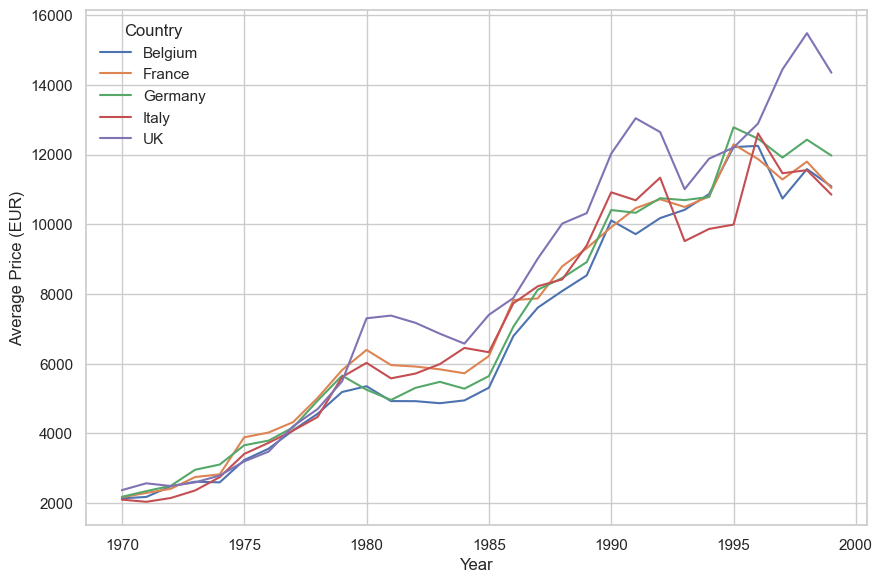

In [11]:
# Average car price by market and year
avg_price = (
    cars.groupby(["ma", "ye"], as_index=False)["eurpr"]
        .mean()
        .dropna(subset=["eurpr"])
)

avg_price["year"] = 1900 + avg_price["ye"]
avg_price["market"] = avg_price["ma"].map(lbl_vals["market"])

fig, ax = plt.subplots(figsize=(9, 6))

for market, data in avg_price.groupby("market"):
    ax.plot(data["year"], data["eurpr"], #marker="o", 
            label=market)

ax.set(xlabel="Year", ylabel="Average Price (EUR)")
ax.legend(title="Country", frameon=False)
fig.tight_layout()
plt.show()

In [12]:

cars["log_eurpr"] = np.log(cars["eurpr"])

# Apply country fixed effects: subtract each country's average log price
cars["price_CFE_resid"] = (
    cars["log_eurpr"]
    - cars.groupby("ma")["log_eurpr"].transform("mean")
)

# Apply time fixed effects: subtract each year's average log price
cars["price_TFE_resid"] = (
    cars["log_eurpr"]
    - cars.groupby("ye")["log_eurpr"].transform("mean")
)

cars["year"] = 1900 + pd.to_numeric(cars["ye"])
cars["market"] = cars["ma"].map(lbl_vals["market"])

In [29]:
# Use the same observations for all comparisons
d = cars.dropna(subset=["ma", "ye", "co", "eurpr"]).copy()
d = d[d["eurpr"] > 0]
d["log_p"] = np.log(d["eurpr"])

fixed_effects = {
    "Country FE": ["ma"],
    "Year FE": ["ye"],
    "Country-year FE": ["ma", "ye"],
    "Product FE": ["brd"],
}

results = []

for label, groups in fixed_effects.items():
    residual = d["log_p"] - d.groupby(groups)["log_p"].transform("mean")
    results.append({
        "Fixed effect": label,
        "Share of variation left": residual.var() / d["log_p"].var()
    })


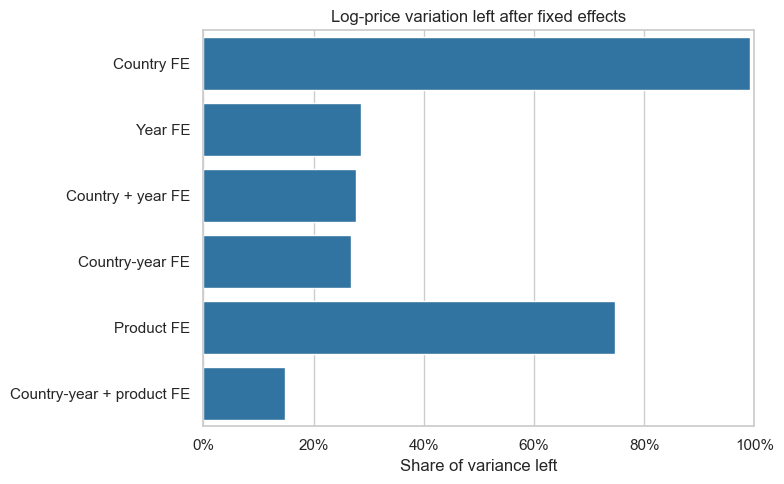

In [32]:
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# Use the same observations for every specification
d = cars.dropna(subset=["ma", "ye", "brd", "eurpr"]).copy()
d = d[d["eurpr"] > 0]
d["log_p"] = np.log(d["eurpr"])
d["market_year"] = d["ma"].astype(str) + "_" + d["ye"].astype(str)

specifications = {
    "Country FE": "C(ma)",
    "Year FE": "C(ye)",
    "Country + year FE": "C(ma) + C(ye)",
    "Country-year FE": "C(market_year)",
    "Product FE": "C(brd)",
    "Country-year + product FE": "C(market_year) + C(brd)",
}

results = []

for name, effects in specifications.items():
    model = smf.ols(f"log_p ~ {effects}", data=d).fit()
    results.append({
        "Fixed effect": name,
        "Share of variation left": 1 - model.rsquared
    })

variation_left = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=variation_left,
    y="Fixed effect",
    x="Share of variation left",
    color="tab:blue",
    ax=ax
)

ax.set_title("Log-price variation left after fixed effects")
ax.set_xlabel("Share of variance left")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))

fig.tight_layout()
plt.show()

In [33]:
variation_left

,Fixed effect,Share of variation left
0,Country FE,0.992003
1,Year FE,0.285686
2,Country + year FE,0.277689
3,Country-year FE,0.267924
4,Product FE,0.747145
5,Country-year + product FE,0.147716


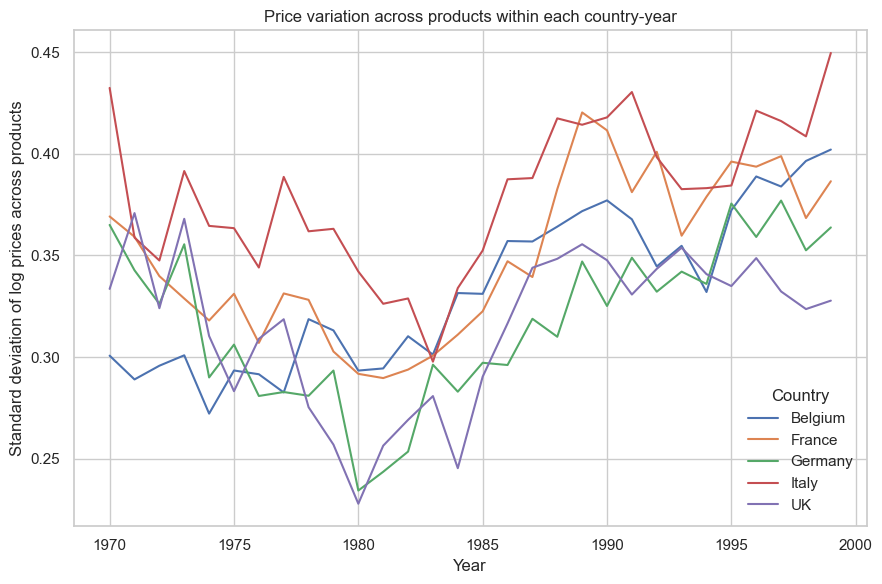

In [31]:
# Prepare prices
d = cars.dropna(subset=["co", "ma", "ye", "eurpr"]).copy()
d = d[d["eurpr"] > 0]
d["year"] = 1900 + d["ye"].astype(int)
d["market"] = d["ma"].map(lbl_vals["market"])
d["log_price"] = np.log(d["eurpr"])

# One price per product, country, and year
product_market_year = (
    d.groupby(["co", "market", "year"], as_index=False)["log_price"]
     .mean()
)



# Plot price differences across products within each country-year
price_spread = (
    product_market_year.groupby(["market", "year"])["log_price"]
    .std()
    .reset_index(name="sd_log_price")
)

fig, ax = plt.subplots(figsize=(9, 6))
sns.lineplot(
    data=price_spread,
    x="year",
    y="sd_log_price",
    hue="market",
    #marker="o",
    errorbar=None,
    ax=ax
)

ax.set(
    xlabel="Year",
    ylabel="Standard deviation of log prices across products",
    title="Price variation across products within each country-year"
)
ax.legend(title="Country", frameon=False)
fig.tight_layout()
plt.show()